# Preprocessing

## Imports


In [1]:
from __future__ import annotations
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
import gzip
import hashlib


In [2]:
import json
import os
import platform
import sys


In [3]:
from scipy.sparse import csc_matrix
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [4]:
import scanpy as sc
import scipy.io as sio
import seaborn as sns

In [5]:
import os
r_home = os.environ.get("R_HOME")
if not r_home:
    raise RuntimeError(
        "Set R_HOME in the shell that starts Jupyter."
    )

r_home_path = Path(r_home).expanduser()
r_executable = r_home_path / "bin" / "x64" / "R.exe"
if not r_executable.is_file():
    raise RuntimeError("R.exe was not found under the configured R_HOME.")

os.environ["R_HOME"] = str(r_home_path)

# Keep the shell-provided library path; do not overwrite it.
r_libs_user = os.environ.get("R_LIBS_USER")
if r_libs_user:
    os.environ["R_LIBS_USER"] = str(Path(r_libs_user).expanduser())

In [6]:
from rpy2.robjects import numpy2ri
from rpy2.robjects.conversion import localconverter
from rpy2.robjects.packages import importr
import rpy2.robjects as ro

In [7]:
import session_info

## Paths


In [8]:
# Papermill injects overrides before any output paths are derived.
sample_id = "GSM4909272_N-MH0021-Total"
    #None

In [9]:
import json

from cap.figures import configure_figure_style, save_figure
from cap.paths import get_paths
from cap.provenance import ( sha256_file, validate_frozen_inputs, write_run_provenance)

paths = get_paths()

if not isinstance(sample_id, str) or not sample_id.strip():
    raise ValueError(
        "Set sample_id to a full library identifier, or run the 000 cohort "
        "and 001 preprocessing driver first."
    )

sample_id = sample_id.strip()

raw_dir = paths.raw_counts_dir
features_file = paths.features_file
policy_file = paths.frozen_dir / "gene_policy.json"
notebook_path = paths.root / "notebooks" / "001_preprocessing.ipynb"

raw_matrix_file = raw_dir / f"{sample_id}-matrix.mtx.gz"
raw_barcodes_file = raw_dir / f"{sample_id}-barcodes.tsv.gz"

paths.require_dir(raw_dir, "GSE161529 filtered count directory")
paths.require_file(features_file, "shared features.tsv")
paths.require_file(policy_file, "frozen gene policy")
paths.require_file(raw_matrix_file, f"matrix for {sample_id}")
paths.require_file(raw_barcodes_file, f"barcodes for {sample_id}")
paths.require_file(notebook_path, "001 preprocessing notebook")

validate_frozen_inputs(paths)

stage_dir = paths.stage_dir("01_preprocessing")
if not stage_dir.is_dir():
    raise RuntimeError(
        "The 01_preprocessing stage has not been prepared. "
        "Start a new run with a fresh CAP_RUN_ID and run 001_Papermill."
    )

head_dir = stage_dir / "h5ad" / "head"
sample_fig_dir = stage_dir / "figures" / "by_sample" / sample_id
sample_table_dir = stage_dir / "tables" / "by_sample" / sample_id

output_file = head_dir / f"{sample_id}.h5ad"
qc_file = sample_table_dir / "qc_summary.csv"

targets = (output_file, sample_fig_dir, sample_table_dir)
existing = [path for path in targets if path.exists()]
if existing:
    relative_paths = [
        path.relative_to(stage_dir).as_posix()
        for path in existing
    ]
    raise FileExistsError(
        "Sample outputs already exist in this run: "
        + ", ".join(relative_paths)
        + ". Start a new run with a fresh CAP_RUN_ID."
    )

head_dir.mkdir(parents=True, exist_ok=True)
sample_fig_dir.mkdir(parents=True, exist_ok=False)
sample_table_dir.mkdir(parents=True, exist_ok=False)

input_files = {
    f"raw_counts/{raw_matrix_file.name}": raw_matrix_file,
    f"raw_counts/{raw_barcodes_file.name}": raw_barcodes_file,
    "features.tsv": features_file,
    "gene_policy.json": policy_file,
}
input_checksums = {
    name: sha256_file(path)
    for name, path in sorted(input_files.items())
}

checksums_file = sample_table_dir / "input_checksums.json"
checksums_file.write_text(
    json.dumps(input_checksums, indent=2, sort_keys=True) + "\n",
    encoding="utf-8",
)


RuntimeError: The 01_preprocessing stage has not been prepared. Start a new run with a fresh CAP_RUN_ID and run 001_Papermill.

In [10]:
import os
import subprocess

print("paths.root:", paths.root)
print("USERPROFILE:", os.environ.get("USERPROFILE"))
print("HOME:", os.environ.get("HOME"))
print("GIT_CONFIG_GLOBAL:", os.environ.get("GIT_CONFIG_GLOBAL"))

for args in (
        ["git", "config", "--show-origin", "--get-all", "safe.directory"],
        ["git", "rev-parse", "HEAD"],
):
    result = subprocess.run(
        args, cwd=paths.root, capture_output=True, text=True
    )
    print(args, "return code:", result.returncode)
    print("stdout:", result.stdout)
    print("stderr:", result.stderr)

paths.root: D:\IdeaProjects\CAP_Submission\CAP_Analysis
USERPROFILE: C:\Users\vonal
HOME: C:\Users\vonal\OneDrive\Documents
GIT_CONFIG_GLOBAL: C:\Users\vonal\.gitconfig
['git', 'config', '--show-origin', '--get-all', 'safe.directory'] return code: 0
stdout: file:"C:\\Users\\vonal\\.gitconfig"	D:/IdeaProjects/CAP_PREVERSION
file:"C:\\Users\\vonal\\.gitconfig"	D:/IdeaProjects/CAP_Submission/CAP_Analysis
file:"C:\\Users\\vonal\\.gitconfig"	D:/IdeaProjects/CAP_Submission/CAP_Analysis

stderr: 
['git', 'rev-parse', 'HEAD'] return code: 0
stdout: 6cfdf2030ff73208423f95259b78dd25bc68b5ae

stderr: 


In [ ]:

write_run_provenance(
    paths,
    sample_table_dir,
    notebook_path=notebook_path,
    input_checksums=input_checksums,
)

configure_figure_style()

In [12]:
importr("SingleCellExperiment")
importr("scDblFinder")
importr("scry")

rpy2.robjects.packages.Package as a <module 'scry'>

In [13]:
def to_r_sparse(mat):
    """Hand a scipy sparse matrix to R as a dgCMatrix without densifying it.

    The dense route needs 11 GB on the largest sample; this needs ~200 MB and
    gives bit-identical results.
    """
    m = csc_matrix(mat)
    return ro.r["new"](
        "dgCMatrix",
        i=ro.IntVector(m.indices.astype(int)),
        p=ro.IntVector(m.indptr.astype(int)),
        x=ro.FloatVector(m.data.astype(float)),
        Dim=ro.IntVector(list(m.shape)),
    )


In [14]:
policy_sha256 = "c4213d53e2d3209312e7781c73ed20f660e0f256042956742693c0e0375926a6"


In [15]:
def load_gene_policy(path=policy_file):
    path = Path(path)
    payload = path.read_bytes()
    digest = hashlib.sha256(payload).hexdigest()
    if digest != policy_sha256:
        raise ValueError(
            "Gene-policy checksum differs from the reviewed source snapshot"
        )
    policy = json.loads(payload)
    policy["sha256"] = digest
    return policy


In [16]:
gene_policy = load_gene_policy()


### Load paths and files

In [17]:
sample_id


'GSM4909272_N-MH0021-Total'

In [18]:
features = pd.read_csv(
    features_file,
    sep="\t",
    header=None,
    names=["gene_id", "symbol", "feature_type"],
)


In [19]:
with gzip.open(raw_dir / f"{sample_id}-matrix.mtx.gz", "rb") as handle:
    x_matrix = sio.mmread(handle).T.tocsr().astype(np.float32)

with gzip.open(raw_dir / f"{sample_id}-barcodes.tsv.gz", "rt") as handle:
    barcodes = [line.strip() for line in handle]

In [20]:
adata = ad.AnnData(
    X=x_matrix,
    obs=pd.DataFrame(index=pd.Index(barcodes, name="barcode")),
    var=features.set_index("symbol"),
)


D:\Conda\envs\cap-rerun\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [21]:
adata.var_names_make_unique()


In [22]:
adata.obs["sample"] = sample_id


In [23]:
adata.obs["condition"] = sample_id.split("_")[1].split("-")[0]


In [24]:
(sample_id, adata.shape)


('GSM4909272_N-MH0021-Total', (2463, 33538))

In [25]:
adata


AnnData object with n_obs × n_vars = 2463 × 33538
    obs: 'sample', 'condition'
    var: 'gene_id', 'feature_type'

### Quality Control

In [26]:
def feature_identities(var, policy):
    """Assign frozen HGNC IDs by stable matrix IDs, without changing var_names."""
    if not var.index.is_unique or "gene_id" not in var:
        raise ValueError(
            "Unique feature names and original Ensembl gene_id values are required"
        )
    ids = var["gene_id"].astype(str).str.split(".").str[0]
    canonical = {}
    for records in policy["symbols"].values():
        for record in records:
            if record["ensembl_id"]:
                canonical.setdefault(record["ensembl_id"], set()).add(record["hgnc_id"])
    values = []
    for identifier in ids:
        identity = policy["feature_hgnc_ids"].get(identifier)
        if identity is None:
            candidates = canonical.get(identifier, set())
            identity = next(iter(candidates)) if len(candidates) == 1 else ""
        values.append(identity)
    return pd.Series(values, index=var.index, name="hgnc_id")


In [27]:
def apply_gene_flags(adata, policy):
    """Replace broad QC prefixes with reviewed family memberships."""
    identity = feature_identities(adata.var, policy)
    audit = pd.DataFrame(
        {
            "feature_gene": adata.var_names.astype(str),
            "feature_id": adata.var["gene_id"].astype(str).to_numpy(),
            "hgnc_id": identity.to_numpy(),
        }
    )
    for flag in ["mt", "ribo", "hb"]:
        old = (
            adata.var[flag].astype(bool).to_numpy()
            if flag in adata.var
            else np.zeros(adata.n_vars, bool)
        )
        new = identity.isin(policy["families"][flag]).to_numpy()
        adata.var[flag] = new
        audit[flag + "_before"] = old
        audit[flag + "_after"] = new
    return audit


In [28]:
gene_flag_audit = apply_gene_flags(adata, gene_policy)


In [29]:
def stamp_gene_policy(adata, policy, stage, cell_cycle_scored=None):
    previous = dict(adata.uns.get("gene_policy", {}))
    previous.update(
        {"version": policy["version"], "sha256": policy["sha256"], "stage": stage}
    )
    if cell_cycle_scored is not None:
        previous["cell_cycle_scored"] = bool(cell_cycle_scored)
    adata.uns["gene_policy"] = previous


In [30]:
stamp_gene_policy(adata, gene_policy, "preprocessing", cell_cycle_scored=False)


In [31]:
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], percent_top=[20], log1p=True, inplace=True
)


Phase scores use the S and G2/M gene sets of Tirosh et al. (2016), computed on a normalised copy so that adata.X retains raw counts. Scoring raw counts makes the score track library size.

In [32]:
def resolve_signature(genes, var, policy):
    """Return unique available feature names and a complete source-member audit.

    Exact original features remain preferred when consistent with the frozen
    identity. Otherwise a unique stable-ID/HGNC match is required. Ambiguities
    stop the run; absent source members remain explicit audit rows.
    """
    identities = feature_identities(var, policy)
    ids = var["gene_id"].astype(str).str.split(".").str[0]
    rows, selected = ([], [])
    for gene in dict.fromkeys(map(str, genes)):
        candidates = policy["symbols"].get(gene, [])
        hgnc_ids = {r["hgnc_id"] for r in candidates}
        expected_ids = {r["ensembl_id"] for r in candidates if r["ensembl_id"]}
        chosen, method = (None, "unavailable")
        if gene in var.index:
            identity = identities.loc[gene]
            if hgnc_ids and identity and (identity not in hgnc_ids):
                raise ValueError(
                    f"Exact feature conflicts with source identity: {gene}"
                )
            chosen, method = (gene, "exact_original_feature")
        else:
            direct = var.index[ids.isin(expected_ids)]
            matches = direct if len(direct) else var.index[identities.isin(hgnc_ids)]
            if len(matches) > 1:
                raise ValueError(
                    f"Ambiguous source-to-feature mapping: {gene}: {list(matches)}"
                )
            if len(matches) == 1:
                chosen = str(matches[0])
                method = (
                    "verified_Ensembl_ID" if len(direct) else "frozen_HGNC_identity"
                )
        duplicate = chosen is not None and chosen in selected
        if chosen is not None and (not duplicate):
            selected.append(chosen)
        rows.append(
            {
                "source_gene": gene,
                "feature_gene": chosen or "",
                "feature_id": str(ids.loc[chosen]) if chosen is not None else "",
                "hgnc_id": identities.loc[chosen] if chosen is not None else "",
                "method": (
                    "duplicate_feature_not_double_weighted" if duplicate else method
                ),
                "used": chosen is not None and (not duplicate),
            }
        )
    return (selected, pd.DataFrame(rows))


In [33]:
def cell_cycle_genes(var, policy):
    s_genes, s_audit = resolve_signature(policy["cell_cycle"]["s.genes"], var, policy)
    g2m_genes, g_audit = resolve_signature(
        policy["cell_cycle"]["g2m.genes"], var, policy
    )
    return (
        s_genes,
        g2m_genes,
        pd.concat(
            [s_audit.assign(phase="S"), g_audit.assign(phase="G2M")], ignore_index=True
        ),
    )


In [34]:
s_genes, g2m_genes, cycle_gene_audit = cell_cycle_genes(adata.var, gene_policy)

In [35]:
assert cycle_gene_audit["used"].all(), (
    "A reviewed cell-cycle member is missing."
)

cycle_gene_audit.to_csv(
    sample_table_dir / "cell_cycle_genes.csv",
    index=False,
    lineterminator="\n",
)


NameError: name 'sample_table_dir' is not defined

In [36]:
tmp = adata.copy()


In [37]:
sc.pp.normalize_total(tmp, target_sum=10000.0)


In [38]:
sc.pp.log1p(tmp)


In [39]:
sc.tl.score_genes_cell_cycle(
    tmp, s_genes=s_genes, g2m_genes=g2m_genes, random_state=0, use_raw=False
)


In [40]:
for col in ["S_score", "G2M_score", "phase"]:
    adata.obs[col] = tmp.obs[col].values


In [41]:
del tmp


In [42]:
stamp_gene_policy(adata, gene_policy, "preprocessing", cell_cycle_scored=True)


### QC plot before filtering

NameError: name 'sample_fig_dir' is not defined

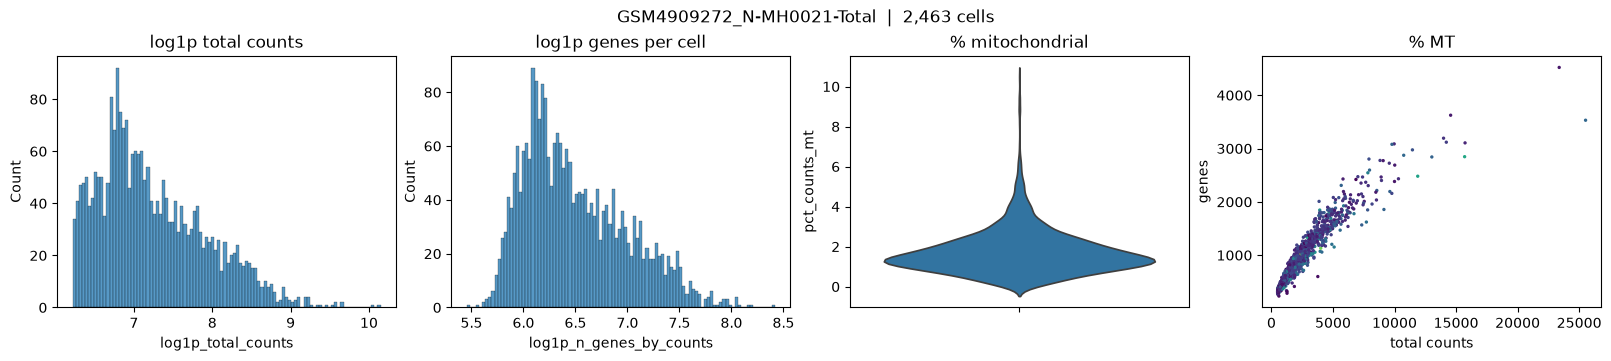

In [43]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), constrained_layout=True)
fig.suptitle(f"{sample_id}  |  {adata.n_obs:,} cells")
sns.histplot(adata.obs["log1p_total_counts"], bins=100, ax=axes[0])
axes[0].set_title("log1p total counts")
sns.histplot(adata.obs["log1p_n_genes_by_counts"], bins=100, ax=axes[1])
axes[1].set_title("log1p genes per cell")
sns.violinplot(y=adata.obs["pct_counts_mt"], ax=axes[2], inner=None)
axes[2].set_title("% mitochondrial")
axes[3].scatter(
    adata.obs["total_counts"],
    adata.obs["n_genes_by_counts"],
    c=adata.obs["pct_counts_mt"],
    s=2,
)
axes[3].set(xlabel="total counts", ylabel="genes", title="% MT")

save_figure(plt.gcf(),
    sample_fig_dir / "qc_before_filtering", rasterize_points=True)
plt.show()


NameError: name 'sample_fig_dir' is not defined

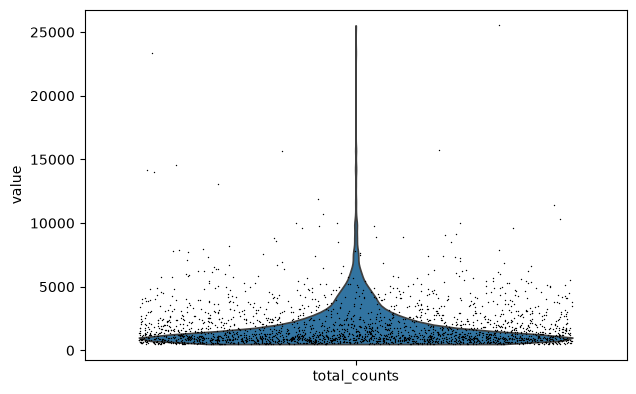

In [44]:
sc.pl.violin(adata, "total_counts", jitter=0.4, show=False)
save_figure(plt.gcf(),
    sample_fig_dir / "violin_total_counts_before_filtering")
plt.show()


In [ ]:
sc.pl.violin(adata, "n_genes_by_counts", jitter=0.4, show=False)
save_figure(plt.gcf(),
    sample_fig_dir / "violin_genes_before_filtering")
plt.show()


In [ ]:
sc.pl.violin(adata, "pct_counts_mt", jitter=0.4, show=False)


save_figure(plt.gcf(),
    sample_fig_dir / "violin_mito_before_filtering")
plt.show()


In [ ]:
sc.pl.violin(adata, "pct_counts_ribo", jitter=0.4, show=False)


save_figure(plt.gcf(),
    sample_fig_dir / "violin_ribo_before_filtering")
plt.show()


In [ ]:
sc.pl.violin(adata, "pct_counts_hb", jitter=0.4, show=False)


save_figure(plt.gcf(),
    sample_fig_dir / "violin_hb_before_filtering")
plt.show()


In [ ]:
sc.pl.scatter(
    adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt", show=False
)
save_figure(plt.gcf(),
    sample_fig_dir / "scatter_counts_vs_genes_before_filtering",
    rasterize_points=True)
plt.show()


In [ ]:
sc.pl.highest_expr_genes(adata, n_top=20, show=False)
save_figure(plt.gcf(),
    sample_fig_dir / "highest_expr_genes_to_genes")
plt.show()


In [ ]:
n_cells = np.asarray((adata.X > 0).sum(axis=0)).ravel()


In [ ]:
plt.figure(figsize=(5, 3.5))
plt.hist(n_cells, bins=100, range=(0, 200))
plt.xlabel("cells expressing the gene")
plt.ylabel("genes")
save_figure(plt.gcf(),
    sample_fig_dir / "histogramm_gene_detection")
plt.show()


In [ ]:
for g in ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]:
    if g in adata.var_names:
        x = np.asarray(adata[:, g].X.todense()).ravel()
        print(
            f"{g:6s} detected in {(x > 0).sum():5d} / {adata.n_obs} cells ({100 * (x > 0).mean():5.2f}%)   max {int(x.max())} UMI"
        )
    else:
        print(f"{g:6s} not in this sample")


## Filter cells

In [45]:
with localconverter(ro.default_converter + numpy2ri.converter):
    ro.globalenv["mito"] = adata.obs["pct_counts_mt"].to_numpy()
    ro.globalenv["ngene"] = adata.obs["n_genes_by_counts"].to_numpy().astype(float)


In [46]:
ro.r(
    """
    suppressMessages({library(miQC); library(SingleCellExperiment)})
    sce <- SingleCellExperiment(assays = list(counts = matrix(0, nrow = 1, ncol = length(mito))))
    colnames(sce) <- as.character(seq_along(mito))
    sce$subsets_mito_percent <- mito
    sce$detected <- ngene
    set.seed(0)
    model <- tryCatch(suppressWarnings(mixtureModel(sce)), error = function(e) NULL)
    miqc_ok <- !is.null(model) && length(model@components) >= 2
    kept <- if (miqc_ok) as.integer(colnames(filterCells(sce, model, verbose = FALSE))) else integer(0)
"""
)


In [47]:
miqc_ok = bool(ro.globalenv["miqc_ok"][0])


In [52]:
if miqc_ok:
    miqc_keep = np.zeros(adata.n_obs, dtype=bool)
    miqc_keep[np.asarray(ro.globalenv["kept"]).astype(int) - 1] = True
else:
    print(
        "miQC could not resolve two components - falling back to a fixed 20% threshold"
    )
    miqc_keep = (adata.obs["pct_counts_mt"] <= 20).to_numpy()


Cells were retained if they passed miQC or had a mitochondrial count fraction below 10%, provided they met the remaining QC criteria. A 20% mitochondrial cutoff was used when miQC fitting failed.


In [48]:
mt_floor = 10


In [53]:
miqc_keep |= (adata.obs["pct_counts_mt"] < mt_floor).to_numpy()


In [54]:
mt_filter_path = "miqc" if miqc_ok else "fixed_20pct"


In [55]:
keep = (
    (adata.obs["total_counts"] >= 500).to_numpy()
    & (adata.obs["total_counts"] <= 40000).to_numpy()
    & (adata.obs["pct_counts_hb"] <= 3).to_numpy()
    & miqc_keep
)


In [56]:
(adata.n_obs, keep.sum(), adata.obs["pct_counts_mt"][keep].max())


(2463, np.int64(2462), np.float32(9.4944515))

In [57]:
adata = adata[keep].copy()


NameError: name 'sample_fig_dir' is not defined

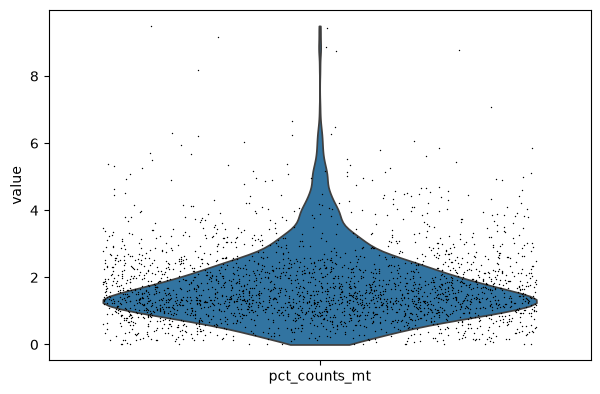

In [58]:
sc.pl.violin(adata, "pct_counts_mt", jitter=0.4, show=False)
save_figure(plt.gcf(),
    sample_fig_dir / "violin_mt_after_filtering")
plt.show()


NameError: name 'sample_fig_dir' is not defined

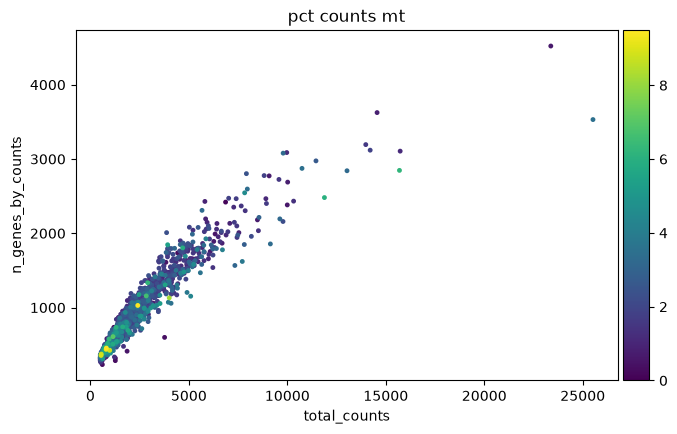

In [59]:
sc.pl.scatter(
    adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt", show=False)
save_figure(plt.gcf(),
    sample_fig_dir / "scatter_counts_vs_genes_after_filtering", rasterize_points=True)
plt.show()


## Doublet removal with scDblFinder

In [60]:
ro.globalenv["counts"] = to_r_sparse(adata.X.T)


In [61]:
ro.r(
    """
    set.seed(0)
    sce <- scDblFinder(SingleCellExperiment(list(counts = counts)))
    doublet_class <- as.character(sce$scDblFinder.class)
    doublet_score <- sce$scDblFinder.score
"""
)


R callback write-console: Creating ~1970 artificial doublets...
  
R callback write-console: Dimensional reduction
  
R callback write-console: Evaluating kNN...
  
R callback write-console: Training model...
  
R callback write-console: iter=0, 263 cells excluded from training.
  
R callback write-console: iter=1, 276 cells excluded from training.
  
R callback write-console: iter=2, 275 cells excluded from training.
  
R callback write-console: Threshold found:0.689
  
R callback write-console: 123 (5%) doublets called
  


In [62]:
adata.obs["doublet_score"] = np.asarray(ro.globalenv["doublet_score"])


In [63]:
adata.obs["doublet_class"] = np.asarray(ro.globalenv["doublet_class"]).astype(str)


In [64]:
assert set(adata.obs["doublet_class"]) <= {"singlet", "doublet"}, set(
    adata.obs["doublet_class"]
)


In [65]:
adata.obs["doublet_class"].value_counts().to_string()


'doublet_class\nsinglet    2339\ndoublet     123'

NameError: name 'sample_fig_dir' is not defined

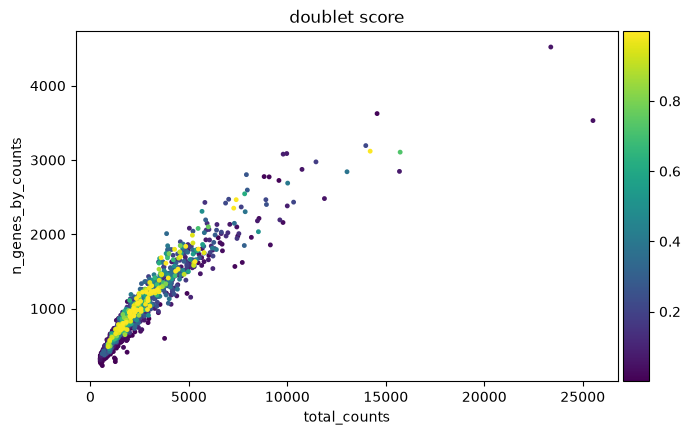

In [66]:
sc.pl.scatter(
    adata, x="total_counts", y="n_genes_by_counts", color="doublet_score", show=False
)
save_figure(plt.gcf(),
    sample_fig_dir / "scatter_doublets", rasterize_points=True)
plt.show()


In [67]:
def pos(g):
    return (
        np.asarray(adata[:, g].X.todense()).ravel() > 0
        if g in adata.var_names
        else np.zeros(adata.n_obs, bool)
    )


In [68]:
dbl = (adata.obs["doublet_class"] == "doublet").to_numpy()


In [69]:
ror1_egfr_dp = pos("ROR1") & pos("EGFR")


In [70]:
epcam_erbb2_dp = pos("EPCAM") & pos("ERBB2")


In [71]:
for name, dp_mask in [("ROR1+EGFR", ror1_egfr_dp), ("EPCAM+ERBB2", epcam_erbb2_dp)]:
    if dp_mask.sum() == 0:
        print(f"{name}: none in this sample")
        continue
    print(
        f"{name}: {dp_mask.sum()} double positive, {100 * dbl[dp_mask].mean():.0f}% of them are doublets (background {100 * dbl.mean():.1f}%)"
    )


ROR1+EGFR: 1 double positive, 0% of them are doublets (background 5.0%)
EPCAM+ERBB2: 11 double positive, 9% of them are doublets (background 5.0%)


In [72]:
n_before_doublets = adata.n_obs


In [73]:
n_doublets = int((adata.obs["doublet_class"] == "doublet").sum())


In [74]:
adata = adata[adata.obs["doublet_class"] == "singlet"].copy()


In [75]:
(adata.n_obs, n_doublets, 100 * n_doublets / n_before_doublets)


(2339, 123, 4.995938261575954)

In [76]:
adata.layers["counts"] = adata.X.copy()


In [77]:
sc.pp.normalize_total(adata, target_sum=10000.0)


In [78]:
sc.pp.log1p(adata)


In [79]:
adata.layers["log1p"] = adata.X.copy()


## Feature selection

In [80]:
ro.globalenv["counts"] = to_r_sparse(adata.layers["counts"].T)


In [81]:
ro.r(
    """
    sce <- SingleCellExperiment(list(counts = counts))
    sce <- devianceFeatureSelection(sce)
    deviance <- rowData(sce)$binomial_deviance
"""
)


In [82]:
adata.var["deviance"] = np.asarray(ro.globalenv["deviance"])


In [83]:
exclude = adata.var[["mt", "ribo", "hb"]].any(axis=1).to_numpy()


In [84]:
exclude |= adata.var_names.isin(s_genes + g2m_genes)


In [85]:
order = np.argsort(adata.var["deviance"].to_numpy())[::-1]


In [86]:
top = order[~exclude[order]][:2000]


In [87]:
adata.var["highly_variable"] = False


In [88]:
adata.var.iloc[top, adata.var.columns.get_loc("highly_variable")] = True


In [89]:
adata.var["highly_variable"].sum()


np.int64(2000)

In [90]:
mean_expr = np.asarray(adata.layers["counts"].mean(axis=0)).ravel()


In [91]:
hv = adata.var["highly_variable"].to_numpy()


NameError: name 'sample_fig_dir' is not defined

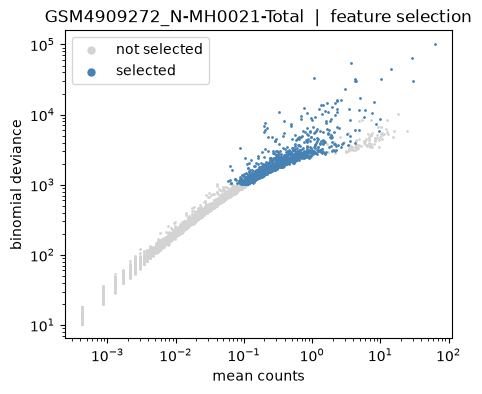

In [92]:
plt.figure(figsize=(5, 4))
plt.scatter(
    mean_expr[~hv], adata.var["deviance"][~hv], s=1, c="lightgrey", label="not selected"
)
plt.scatter(
    mean_expr[hv], adata.var["deviance"][hv], s=1, c="steelblue", label="selected"
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("mean counts")
plt.ylabel("binomial deviance")
plt.title(f"{sample_id}  |  feature selection")
plt.legend(markerscale=5)
save_figure(plt.gcf(),
    sample_fig_dir / "scatter_deviance", rasterize_points=True)
plt.show()


## PCA and depth check

In [93]:
sc.pp.pca(adata, n_comps=50, mask_var="highly_variable", random_state=0)


In [94]:
r = np.corrcoef(adata.obsm["X_pca"][:, 0], adata.obs["total_counts"])[0, 1]


In [95]:
r


np.float64(-0.18189928447746137)

NameError: name 'sample_fig_dir' is not defined

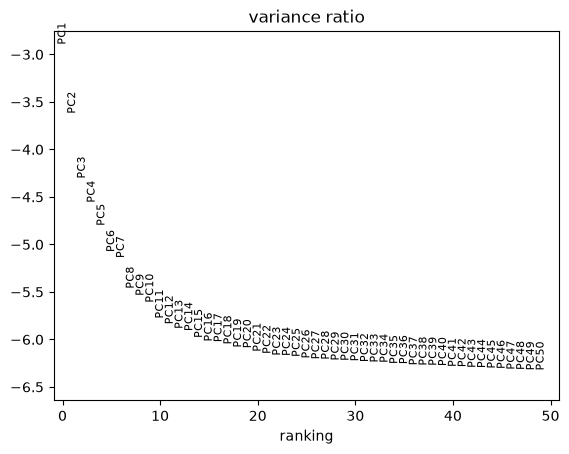

In [96]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True, show=False)
save_figure(plt.gcf(),
    sample_fig_dir / "pca_variance_ratio", rasterize_points=True)
plt.show()


NameError: name 'sample_fig_dir' is not defined

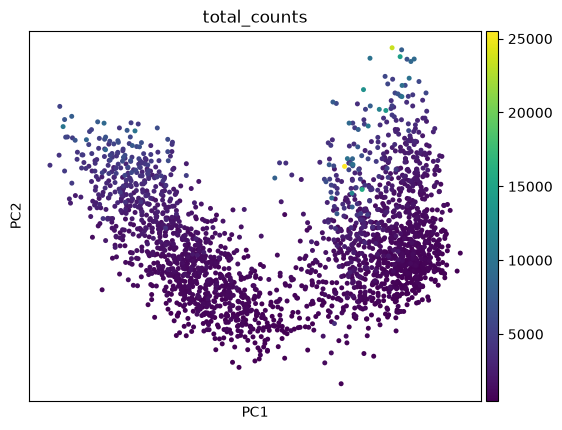

In [97]:
sc.pl.pca(adata, color="total_counts", show=False)
save_figure(plt.gcf(),
    sample_fig_dir / "pca_depth", rasterize_points=True)
plt.show()


NameError: name 'sample_fig_dir' is not defined

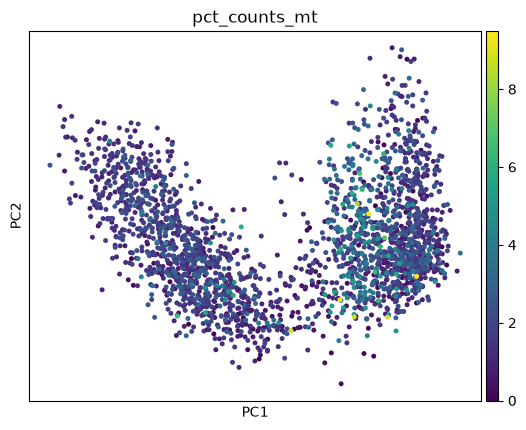

In [98]:
sc.pl.pca(adata, color="pct_counts_mt", show=False)
save_figure(plt.gcf(),
    sample_fig_dir / "pca_mito", rasterize_points=True)
plt.show()


## Save

In [99]:
adata.X = adata.layers["counts"].copy()


In [100]:
temporary_file = output_file.with_suffix(".tmp.h5ad")

try:
    adata.write_h5ad(temporary_file)
    temporary_file.replace(output_file)
finally:
    if temporary_file.exists():
        temporary_file.unlink()

NameError: name 'output_file' is not defined

In [101]:
adata


AnnData object with n_obs × n_vars = 2339 × 33538
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class'
    var: 'gene_id', 'feature_type', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'deviance', 'highly_variable'
    uns: 'gene_policy', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts', 'log1p'

In [102]:
qc_summary = pd.DataFrame(
    [
        {
            "sample_id": sample_id,
            "condition": str(adata.obs["condition"].iloc[0]),
            "n_cells_final": adata.n_obs,
            "n_genes": adata.n_vars,
            "max_retained_pct_mt": round(float(adata.obs["pct_counts_mt"].max()), 1),
            "pct_doublets": round(100 * n_doublets / n_before_doublets, 1),
            "pc1_depth_corr": round(float(r), 3),
            "median_counts": int(adata.obs["total_counts"].median()),
            "median_genes": int(adata.obs["n_genes_by_counts"].median()),
            "miqc_converged": miqc_ok,
            "mt_filter_path": mt_filter_path,
            "mt_floor": mt_floor,
        }
    ]
)

qc_summary.to_csv(qc_file, index=False, lineterminator="\n")

NameError: name 'qc_file' is not defined

In [ ]:
print("\n".join(ro.r("capture.output(sessionInfo())")))


In [ ]:
session_info.show(
    excludes=["builtins", "stdlib_list", "SingleCellExperiment", "scDblFinder", "scry"]
)
